<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch07_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch07_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 7 Figures — Colab Notebook
**The Standard Model · Chapter 7: Neutrinos**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch07/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §7.3    | Neutrino oscillation probability $P(\nu_\alpha\to\nu_\beta)$ vs $L/E$ for all flavour channels |
| fig02  | §7.2    | PMNS matrix: magnitude table, mass hierarchy (normal/inverted), mixing angles |
| fig03  | §7.4    | Seesaw mechanism: Majorana mass scales, leptogenesis, effective $m_{\beta\beta}$ vs $m_{\rm lightest}$ |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Circle
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
import os

# ── Dark palette (Standard Model series — teal/cyan accent) ───────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch07'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')

Setup complete. Palette and output directory ready.


---
## fig01 · Neutrino Oscillation Probabilities (§7.3)

**Left**: $P(\nu_e\to\nu_\mu)$, $P(\nu_e\to\nu_\tau)$, $P(\nu_e\to\nu_e)$ vs $L/E$ —
solar and atmospheric oscillation lengths marked  
**Middle**: 2-flavour approximation for atmospheric $\nu_\mu\to\nu_\tau$ —
showing $\sin^2(2\theta_{23})$ and $\Delta m^2_{32}$  
**Right**: Experimental regimes — solar, reactor, atmospheric, accelerator baselines

  saved -> figures/ch07/fig01_neutrino_oscillation.png


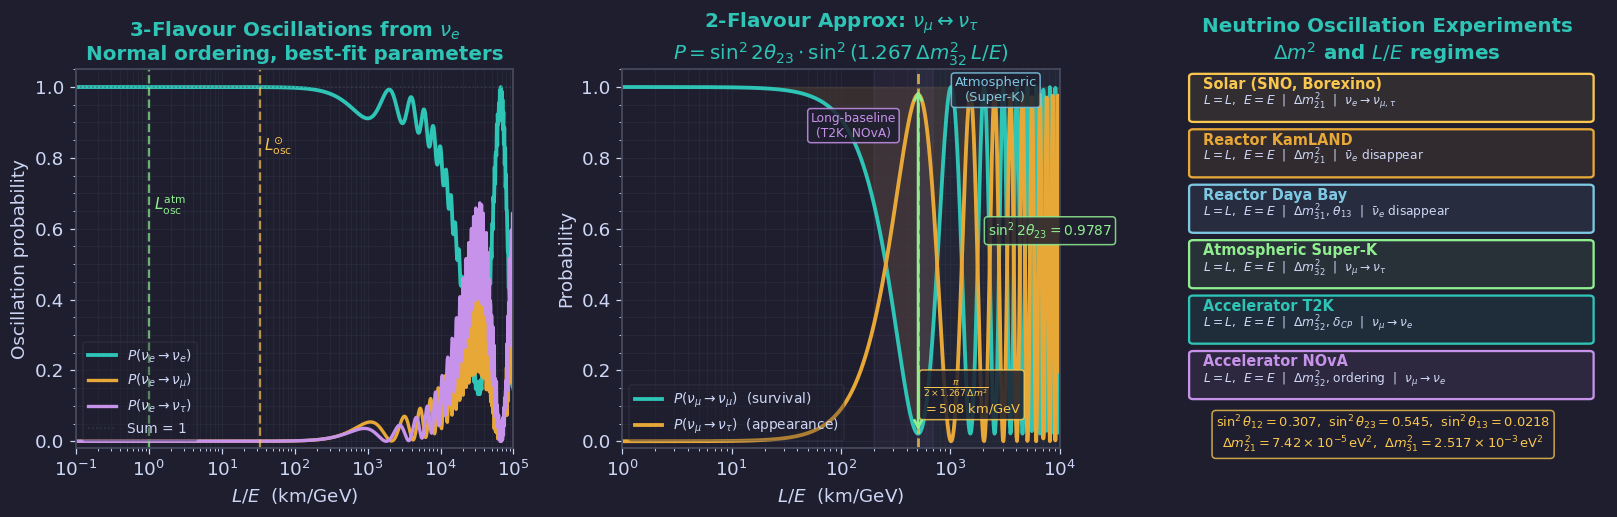

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# Best-fit PMNS parameters (NuFIT 5.2, normal ordering)
th12 = np.radians(33.44)   # solar
th23 = np.radians(49.2)    # atmospheric
th13 = np.radians(8.57)    # reactor
dCP  = np.radians(194.0)   # CP phase (degrees)

# Mass squared differences (eV^2)
dm21_sq = 7.42e-5    # solar
dm31_sq = 2.517e-3   # atmospheric (normal ordering)
dm32_sq = dm31_sq - dm21_sq

# PMNS matrix
c12, s12 = np.cos(th12), np.sin(th12)
c23, s23 = np.cos(th23), np.sin(th23)
c13, s13 = np.cos(th13), np.sin(th13)
eid = np.exp(1j * dCP)

U = np.array([
    [c12*c13,                    s12*c13,                   s13*np.exp(-1j*dCP)],
    [-s12*c23 - c12*s23*s13*eid, c12*c23 - s12*s23*s13*eid, s23*c13           ],
    [s12*s23  - c12*c23*s13*eid, -c12*s23 - s12*c23*s13*eid, c23*c13          ]
])

def osc_prob(alpha, beta, L_over_E_km_GeV):
    """
    Oscillation probability P(nu_alpha -> nu_beta)
    L/E in km/GeV, delta_m^2 in eV^2
    Phase: 1.267 * dm^2 [eV^2] * L[km] / E[GeV]
    """
    dm_sq = np.array([0, dm21_sq, dm31_sq])  # m1=0 reference
    total = 0.0 + 0.0j
    for k in range(3):
        total += U[alpha, k] * np.conj(U[beta, k]) * np.exp(-1j * 1.267 * dm_sq[k] * L_over_E_km_GeV)
    return np.abs(total)**2

# L/E range (km/GeV)
LoE = np.logspace(-1, 5, 1000)

# ── Left: full 3-flavour from nu_e ────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

P_ee  = np.array([osc_prob(0, 0, x) for x in LoE])
P_emu = np.array([osc_prob(0, 1, x) for x in LoE])
P_eta = np.array([osc_prob(0, 2, x) for x in LoE])

ax.semilogx(LoE, P_ee,  color=TEAL,   lw=2.5, label=r'$P(\nu_e\to\nu_e)$')
ax.semilogx(LoE, P_emu, color=ORANGE, lw=2.2, label=r'$P(\nu_e\to\nu_\mu)$')
ax.semilogx(LoE, P_eta, color=PURPLE, lw=2.2, label=r'$P(\nu_e\to\nu_\tau)$')

# Probability sum = 1
ax.semilogx(LoE, P_ee + P_emu + P_eta, color=EDGE,
            lw=1.0, ls=':', alpha=0.6, label='Sum = 1')

# Solar oscillation length (~L/E ~ 10^4 km/GeV for dm21)
LoE_solar = np.pi / (1.267 * dm21_sq) * 1e-3  # ~15000 km/GeV
ax.axvline(LoE_solar, color=YELLOW, lw=1.5, ls='--', alpha=0.7)
ax.text(LoE_solar*1.15, 0.82, r'$L_{\rm osc}^{\odot}$', color=YELLOW, fontsize=10)

# Atmospheric
LoE_atm = np.pi / (1.267 * dm32_sq) * 1e-3
ax.axvline(LoE_atm, color=GREEN, lw=1.5, ls='--', alpha=0.7)
ax.text(LoE_atm*1.15, 0.65, r'$L_{\rm osc}^{\rm atm}$', color=GREEN, fontsize=10)

ax.set_xlabel(r'$L/E$  (km/GeV)')
ax.set_ylabel(r'Oscillation probability')
ax.set_title(r'3-Flavour Oscillations from $\nu_e$' + '\n'
             'Normal ordering, best-fit parameters', color=TEAL)
ax.legend(fontsize=9, labelcolor=FG, loc='lower left')
ax.set_xlim(0.1, 1e5)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, alpha=0.2, which='both')

# ── Middle: 2-flavour atmospheric nu_mu -> nu_tau ─────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# P(nu_mu -> nu_tau) 2-flavour: sin^2(2theta23) * sin^2(1.267 dm32^2 L/E)
sin2_2th23 = np.sin(2*th23)**2

LoE_atm_range = np.logspace(0, 4, 800)
phase_atm = 1.267 * dm32_sq * LoE_atm_range

P_mutau_2f = sin2_2th23 * np.sin(phase_atm)**2
P_mumu_2f  = 1 - P_mutau_2f

ax2.semilogx(LoE_atm_range, P_mumu_2f,  color=TEAL,   lw=2.5,
             label=r'$P(\nu_\mu\to\nu_\mu)$  (survival)')
ax2.semilogx(LoE_atm_range, P_mutau_2f, color=ORANGE, lw=2.5,
             label=r'$P(\nu_\mu\to\nu_\tau)$  (appearance)')

# Fill between
ax2.fill_between(LoE_atm_range, P_mumu_2f, 1,
                 color=ORANGE, alpha=0.12)

# First minimum of P_mumu
LoE_min = np.pi / (2 * 1.267 * dm32_sq)
ax2.axvline(LoE_min, color=YELLOW, lw=1.8, ls='--', alpha=0.8)
ax2.text(LoE_min * 1.1, 0.08,
         r'$\frac{\pi}{2\times1.267\,\Delta m^2}$' + '\n' + f'$={LoE_min:.0f}$ km/GeV',
         color=YELLOW, fontsize=8.5,
             bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=YELLOW,
        alpha=0.85
    ))

# Amplitude annotation
ax2.annotate('', xy=(LoE_min, 1 - sin2_2th23),
             xytext=(LoE_min, 1.0),
             arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.8))
# ax2.text(LoE_min * 3, 0.55,
#          r'$\sin^2 2\theta_{23}$' + f'$= {sin2_2th23:.4f}$',
#          color=GREEN, fontsize=9)
ax2.text(
    2200, 0.58,
    r'$\sin^2 2\theta_{23}$' + f'$= {sin2_2th23:.4f}$',
    color=GREEN,
    fontsize=9,
    bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=GREEN,
        alpha=0.85
    )
)

# Experimental regimes
# ax2.axvspan(500, 13000, alpha=0.06, color=BLUE)
# ax2.text(2000, 0.92, 'Atmospheric\n(Super-K)', color=BLUE, fontsize=8.5, ha='center')
# ax2.axvspan(200, 700, alpha=0.06, color=PURPLE)
# ax2.text(350, 0.82, 'Long-baseline\n(T2K, NOvA)', color=PURPLE, fontsize=8, ha='center')

# Experimental regimes
ax2.axvspan(500, 13000, alpha=0.05, color=BLUE)

ax2.text(
    2600, 0.96,
    'Atmospheric\n(Super-K)',
    color=BLUE,
    fontsize=8.5,
    ha='center',
    bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=BLUE,
        alpha=0.85
    )
)

ax2.axvspan(200, 700, alpha=0.05, color=PURPLE)

ax2.text(
    130, 0.86,
    'Long-baseline\n(T2K, NOvA)',
    color=PURPLE,
    fontsize=8,
    ha='center',
    bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=PURPLE,
        alpha=0.85
    )
)

ax2.set_xlabel(r'$L/E$  (km/GeV)')
ax2.set_ylabel(r'Probability')
ax2.set_title(r'2-Flavour Approx: $\nu_\mu\leftrightarrow\nu_\tau$' + '\n'
              r'$P = \sin^2 2\theta_{23}\cdot\sin^2(1.267\,\Delta m^2_{32}\,L/E)$',
              color=TEAL)
ax2.legend(fontsize=9, labelcolor=FG, loc="lower left")
ax2.set_xlim(1, 1e4)
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True, alpha=0.2, which='both')

# ── Right: experimental regimes summary ───────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.3, 5.0)
ax3.set_ylim(-0.5, 6.2)
ax3.axis('off')
ax3.set_title('Neutrino Oscillation Experiments\n'
              r'$\Delta m^2$ and $L/E$ regimes', color=TEAL)

expts = [
    # name, L(km), E(MeV), dm^2 target, type, colour
    ('Solar (SNO, Borexino)', r'$1.5\times10^8$', '~10 MeV',
     r'$\Delta m^2_{21}$', r'$\nu_e\to\nu_{\mu,\tau}$', YELLOW),
    ('Reactor KamLAND',      '~180 km',          '~3 MeV',
     r'$\Delta m^2_{21}$', r'$\bar\nu_e$ disappear', ORANGE),
    ('Reactor Daya Bay',     '~1.5 km',          '~3 MeV',
     r'$\Delta m^2_{31}$, $\theta_{13}$', r'$\bar\nu_e$ disappear', BLUE),
    ('Atmospheric Super-K',  '~10–10000 km',      '~1 GeV',
     r'$\Delta m^2_{32}$', r'$\nu_\mu\to\nu_\tau$', GREEN),
    ('Accelerator T2K',      '295 km',            '~0.6 GeV',
     r'$\Delta m^2_{32}$, $\delta_{CP}$', r'$\nu_\mu\to\nu_e$', TEAL),
    ('Accelerator NOvA',     '810 km',            '~2 GeV',
     r'$\Delta m^2_{32}$, ordering', r'$\nu_\mu\to\nu_e$', PURPLE),
]

for i, (name, L, E, dm, chan, col) in enumerate(expts):
    y = 5.7 - i * 0.98
    rect = FancyBboxPatch((0.0, y - 0.38), 4.8, 0.75,
                          boxstyle='round,pad=0.05',
                          lw=1.5, edgecolor=col, facecolor=col+'18')
    ax3.add_patch(rect)
    ax3.text(0.12, y + 0.15, name, color=col, fontsize=9.5, fontweight='bold')
    ax3.text(0.12, y - 0.14,
             rf'$L={{L}}$,  $E={{E}}$  |  {dm}  |  {chan}',
             color=FG, fontsize=8)

# Best-fit summary box
ax3.text(2.3, -0.5,
         r'$\sin^2\theta_{12}=0.307$,  $\sin^2\theta_{23}=0.545$,  $\sin^2\theta_{13}=0.0218$' + '\n'
         r'$\Delta m^2_{21}=7.42\times10^{-5}\,{\rm eV}^2$,  '
         r'$\Delta m^2_{31}=2.517\times10^{-3}\,{\rm eV}^2$',
         ha='center', color=YELLOW, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=BG, ec=YELLOW, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig01_neutrino_oscillation.png', fig)

---
## fig02 · PMNS Matrix and Mass Hierarchy (§7.2)

**Left**: $|U_{\alpha i}|^2$ matrix — colour-coded with PDG best-fit values  
**Middle**: Normal vs inverted mass hierarchy — mass eigenstate composition in flavour  
**Right**: $\Delta m^2$ measurements — solar vs atmospheric scale, absolute mass bound

  saved -> figures/ch07/fig02_pmns_matrix.png


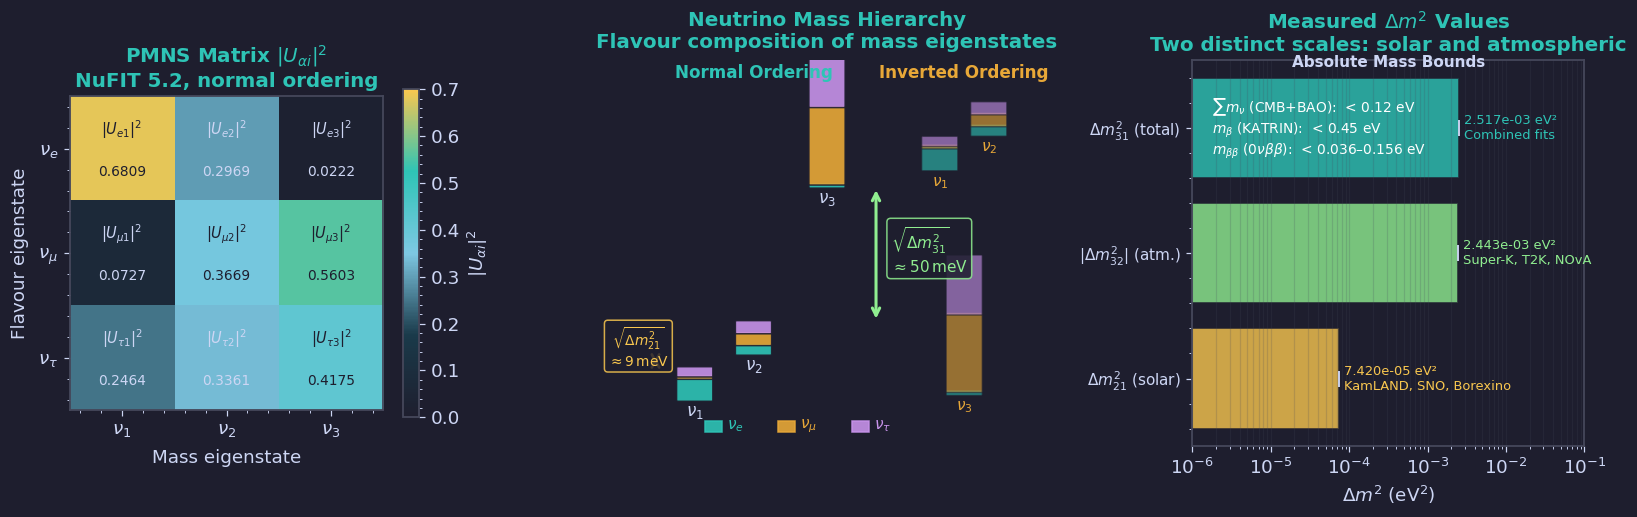

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# PMNS |U|^2 matrix
Uabs2 = np.abs(U)**2

# ── Left: |U_alpha_i|^2 heat map ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

cmap_pmns = LinearSegmentedColormap.from_list(
    'pmns', [BG, '#1a3a4a', BLUE, TEAL, YELLOW], N=256)

im = ax.imshow(Uabs2, cmap=cmap_pmns, vmin=0, vmax=0.7, aspect='equal')
plt.colorbar(im, ax=ax, label=r'$|U_{\alpha i}|^2$', shrink=0.85)

row_lbl = [r'$\nu_e$', r'$\nu_\mu$', r'$\nu_\tau$']
col_lbl = [r'$\nu_1$', r'$\nu_2$', r'$\nu_3$']
pmns_names = [
    [r'$|U_{e1}|^2$',   r'$|U_{e2}|^2$',   r'$|U_{e3}|^2$'],
    [r'$|U_{\mu1}|^2$', r'$|U_{\mu2}|^2$', r'$|U_{\mu3}|^2$'],
    [r'$|U_{\tau1}|^2$',r'$|U_{\tau2}|^2$',r'$|U_{\tau3}|^2$'],
]

for i in range(3):
    for j in range(3):
        val = Uabs2[i, j]
        tc  = BG if val > 0.35 else FG
        ax.text(j, i - 0.18, pmns_names[i][j],
                ha='center', va='center', color=tc,
                fontsize=9.5, fontweight='bold')
        ax.text(j, i + 0.22, f'{val:.4f}',
                ha='center', va='center', color=tc, fontsize=9)

ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
ax.set_xticklabels(col_lbl, fontsize=12)
ax.set_yticklabels(row_lbl, fontsize=12)
ax.set_xlabel('Mass eigenstate', labelpad=6)
ax.set_ylabel('Flavour eigenstate', labelpad=6)
ax.set_title(r'PMNS Matrix $|U_{\alpha i}|^2$' + '\n'
             'NuFIT 5.2, normal ordering', color=TEAL)

# Normal ordering y-levels (schematic mass scale)
y_NO = [0.3, 1.0, 4.2]   # m1, m2, m3  (large gap m2->m3)
dm21_h = 0.35   # height proportional to sqrt(dm21^2)
dm31_h = 1.5    # height proportional to sqrt(dm31^2)

heights = [dm21_h * 0.5, dm21_h * 0.5, dm31_h * 0.5]

# ── Middle: improved mass hierarchy diagram ───────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_xlim(-0.5, 7.5)
ax2.set_ylim(-0.4, 6.3)
ax2.axis('off')

ax2.set_title(
    'Neutrino Mass Hierarchy\nFlavour composition of mass eigenstates',
    color=TEAL,
    pad=8
)

bar_w = 0.7

flavour_cols = [TEAL, ORANGE, PURPLE]
flavour_lbls = [r'$\nu_e$', r'$\nu_\mu$', r'$\nu_\tau$']

# ------------------------------------------------------------------
# NORMAL ORDERING
# ------------------------------------------------------------------

x_NO = [0.8, 2.0, 3.5]
y_NO = [0.4, 1.2, 4.1]

ax2.text(
    2.0, 6.0,
    'Normal Ordering',
    ha='center',
    color=TEAL,
    fontsize=11,
    fontweight='bold'
)

for i, (x, yb, h) in enumerate(zip(x_NO, y_NO, heights)):

    bottom = yb

    for alpha in range(3):

        frac = Uabs2[alpha, i]
        seg_h = frac * h * 3.2

        rect = FancyBboxPatch(
            (x - bar_w/2, bottom),
            bar_w,
            seg_h,
            boxstyle='round,pad=0.02',
            linewidth=1.0,
            edgecolor=BG,
            facecolor=flavour_cols[alpha],
            alpha=0.90
        )

        ax2.add_patch(rect)
        bottom += seg_h

    ax2.text(
        x,
        yb - 0.28,
        [r'$\nu_1$', r'$\nu_2$', r'$\nu_3$'][i],
        ha='center',
        color=FG,
        fontsize=11,
        fontweight='bold'
    )

# Atmospheric gap
ax2.annotate(
    '',
    xy=(4.5, y_NO[2]),
    xytext=(4.5, y_NO[1] + heights[1]*3.2),
    arrowprops=dict(
        arrowstyle='<->',
        color=GREEN,
        lw=2.0
    )
)

ax2.text(
    4.8,
    3.0,
    r'$\sqrt{\Delta m^2_{31}}$' '\n'
    r'$\approx 50\,{\rm meV}$',
    color=GREEN,
    fontsize=10,
    va='center',
    bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=GREEN,
        alpha=0.85
    )
)

# Solar gap
ax2.annotate(
    '',
    xy=(0.0, y_NO[1]),
    xytext=(0.0, y_NO[0] + heights[0]*3.2),
    arrowprops=dict(
        arrowstyle='<->',
        color=YELLOW,
        lw=1.8
    )
)

ax2.text(
    -0.35,
    1.0,
    r'$\sqrt{\Delta m^2_{21}}$' '\n'
    r'$\approx 9\,{\rm meV}$',
    color=YELLOW,
    fontsize=9,
    ha='center',
    bbox=dict(
        boxstyle='round,pad=0.25',
        fc=BG,
        ec=YELLOW,
        alpha=0.85
    )
)

# ------------------------------------------------------------------
# INVERTED ORDERING
# ------------------------------------------------------------------

x_IO = [5.8, 6.8, 6.3]
y_IO = [4.4, 5.0, 0.5]

ax2.text(
    6.3, 6.0,
    'Inverted Ordering',
    ha='center',
    color=ORANGE,
    fontsize=11,
    fontweight='bold'
)

for i, (x, yb, h) in enumerate(zip(x_IO, y_IO, heights)):

    bottom = yb

    for alpha in range(3):

        frac = Uabs2[alpha, i]
        seg_h = frac * h * 3.2

        rect = FancyBboxPatch(
            (x - bar_w/2, bottom),
            bar_w,
            seg_h,
            boxstyle='round,pad=0.02',
            linewidth=1.0,
            edgecolor=BG,
            facecolor=flavour_cols[alpha],
            alpha=0.60
        )

        ax2.add_patch(rect)
        bottom += seg_h

    ax2.text(
        x,
        yb - 0.28,
        [r'$\nu_1$', r'$\nu_2$', r'$\nu_3$'][i],
        ha='center',
        color=ORANGE,
        fontsize=10
    )

# ------------------------------------------------------------------
# Legend
# ------------------------------------------------------------------

legend_y = -0.15

for k, (col, lbl) in enumerate(zip(flavour_cols, flavour_lbls)):

    ax2.add_patch(
        plt.Rectangle(
            (1.0 + k*1.5, legend_y),
            0.35,
            0.18,
            color=col,
            alpha=0.9
        )
    )

    ax2.text(
        1.45 + k*1.5,
        legend_y + 0.09,
        lbl,
        color=col,
        fontsize=10,
        va='center'
    )

# ── Right: mass-squared differences summary ───────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Log-scale bar chart of mass-squared differences and absolute constraints
params = [
    (r'$\Delta m^2_{21}$ (solar)',    dm21_sq,     1e-6,  YELLOW,
     r'KamLAND, SNO, Borexino'),
    (r'$|\Delta m^2_{32}|$ (atm.)',   abs(dm32_sq),1e-5,  GREEN,
     r'Super-K, T2K, NOvA'),
    (r'$\Delta m^2_{31}$ (total)',     dm31_sq,     1e-5,  TEAL,
     r'Combined fits'),
]

y_r = np.arange(len(params))
vals_r  = [p[1] for p in params]
errs_r  = [p[2] for p in params]
cols_r  = [p[3] for p in params]

ax3.barh(y_r, vals_r, xerr=errs_r, color=cols_r, alpha=0.80,
         edgecolor=BG, lw=1.2,  error_kw={'ecolor': FG, 'elinewidth': 1.5, 'capsize': 5})

for i, (p, v) in enumerate(zip(params, vals_r)):
    ax3.text(v * 1.15, i,
             f'{v:.3e} eV²\n{p[4]}',
             va='center', color=p[3], fontsize=8.5)

ax3.set_yticks(y_r)
ax3.set_yticklabels([p[0] for p in params], fontsize=10)
ax3.set_xlabel(r'$\Delta m^2$ (eV$^2$)')
ax3.set_xscale('log')
ax3.set_title(r'Measured $\Delta m^2$ Values' + '\n'
              'Two distinct scales: solar and atmospheric', color=TEAL)
ax3.set_xlim(1e-6, 1e-1)
ax3.grid(True, alpha=0.2, which='both', axis='x')

# Absolute mass constraints
ax3_top = ax3.inset_axes([0.0, 0.55, 1.0, 0.42])
ax3_top.set_facecolor(BG)

mass_bounds = [
    (r'$\sum m_\nu$ (CMB+BAO)', '< 0.12 eV', "white"),
    (r'$m_\beta$ (KATRIN)',     '< 0.45 eV', "white"),
    (r'$m_{\beta\beta}$ ($0\nu\beta\beta$)', '< 0.036–0.156 eV', "white"),
]

for k, (lbl, val, col) in enumerate(mass_bounds):
    ax3_top.text(0.05, 0.75 - k*0.13, lbl + ':  ' + val,
                 color=col, fontsize=9, transform=ax3_top.transAxes)

ax3_top.set_title('Absolute Mass Bounds', color=FG, fontsize=10, pad=3)
ax3_top.axis('off')

plt.tight_layout(pad=1.5)
save('fig02_pmns_matrix.png', fig)

---
## fig03 · Seesaw Mechanism and Leptogenesis (§7.4)

**Left**: Type-I seesaw mass scales — light $m_\nu \sim v^2/M_R$ vs heavy $M_R$  
**Middle**: Effective $m_{\beta\beta}$ (neutrinoless double beta decay) vs lightest neutrino mass — normal and inverted ordering bands  
**Right**: Leptogenesis schematic — heavy $N$ decay → lepton asymmetry → baryon asymmetry

  saved -> figures/ch07/fig03_seesaw.png


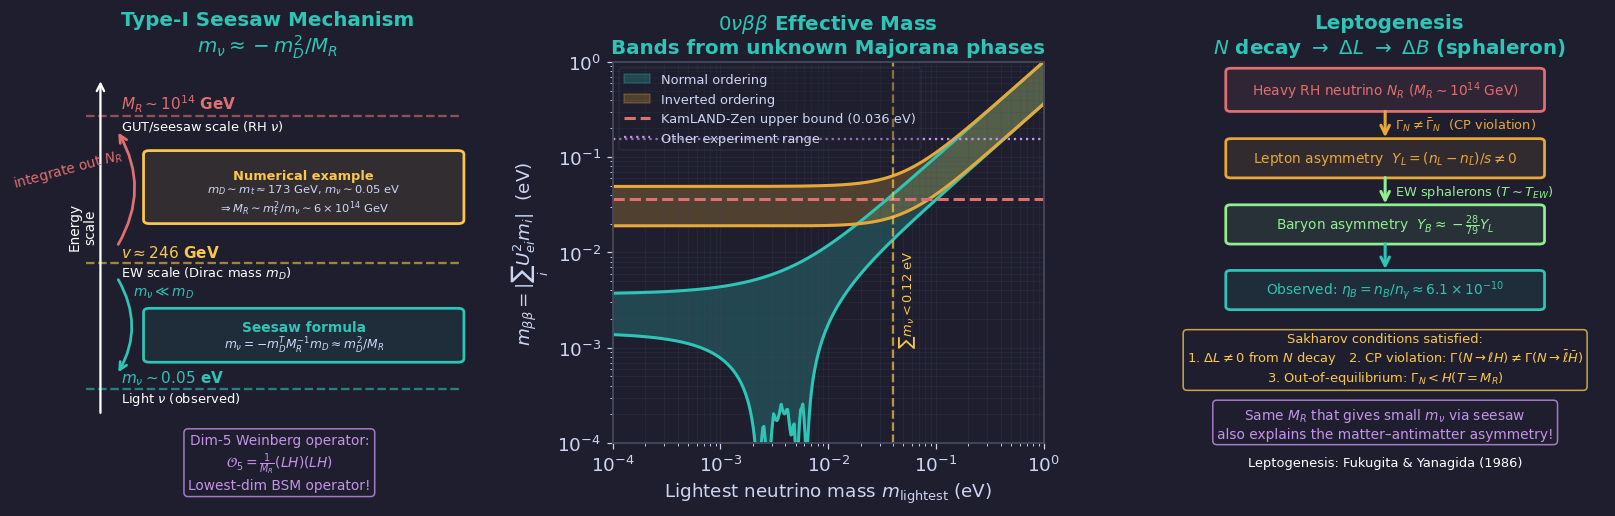

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

def fbox(ax,x,y,w,h,title,body,col,fs=9):
    rect = FancyBboxPatch((x-w/2,y-h/2),w,h,
                          boxstyle='round,pad=0.07',
                          lw=1.8,edgecolor=col,facecolor=col+'18')
    ax.add_patch(rect)
    ax.text(x,y+h*0.18,title,ha='center',va='center',
            color=col,fontsize=fs,fontweight='bold')
    ax.text(x,y-h*0.20,body,ha='center',va='center',
            color=FG,fontsize=fs-1.0)

def farr(ax,x1,y1,x2,y2,col,lbl=''):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->',color=col,lw=2.0,mutation_scale=14))
    if lbl:
        ax.text((x1+x2)/2+0.1,(y1+y2)/2,lbl,color=col,fontsize=9)

# ── Left: seesaw mass scales ───────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 5.0)
ax.set_ylim(-0.5, 6.5)
ax.axis('off')
ax.set_title('Type-I Seesaw Mechanism\n'
             r'$m_\nu \approx -m_D^2/M_R$', color=TEAL)

# Energy scale axis (schematic, vertical)
ax.annotate('', xy=(0.3, 6.2), xytext=(0.3, 0.0),
            arrowprops=dict(arrowstyle='->', color="white", lw=1.5))
ax.text(0.08, 3.1, 'Energy\nscale', color="white", fontsize=9,
        ha='center', rotation=90)

# Mass scales
scales = [
    (0.3, r'$m_\nu\sim0.05$ eV',  TEAL,   r'Light $\nu$ (observed)'),
    (2.2, r'$v\approx246$ GeV',   YELLOW, r'EW scale (Dirac mass $m_D$)'),
    (5.0, r'$M_R\sim10^{14}$ GeV',RED,    r'GUT/seesaw scale (RH $\nu$)'),
]
y_scales = [0.5, 2.8, 5.5]
for (y, lbl, col, note) in zip(y_scales, [s[1] for s in scales],
                                [s[2] for s in scales],
                                [s[3] for s in scales]):
    ax.axhline(y, xmin=0.08, xmax=0.95,
               color=col, lw=1.5, ls='--', alpha=0.6)
    ax.text(0.55, y + 0.12, lbl,  color=col,  fontsize=10, fontweight='bold')
    ax.text(0.55, y - 0.25, note, color="white", fontsize=8.5)

# Seesaw relation box
fbox(ax, 2.8, 1.48, 3.8, 0.85,
     r'Seesaw formula',
     r'$m_\nu = -m_D^T M_R^{-1} m_D \approx m_D^2/M_R$',
     TEAL, fs=9)

# Numerical example
fbox(ax, 2.8, 4.2, 3.8, 1.2,
     r'Numerical example',
     r'$m_D\sim m_t\approx173$ GeV, $m_\nu\sim0.05$ eV' + '\n'
     r'$\Rightarrow M_R\sim m_t^2/m_\nu\sim6\times10^{14}$ GeV',
     YELLOW, fs=8.5)

# Arrows showing the seesaw
ax.annotate('', xy=(0.5, 5.25), xytext=(0.5, 3.1),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.8,
                            connectionstyle='arc3,rad=0.3'))
ax.text(-0.8, 4.2, r'integrate out $N_R$', color=RED, fontsize=9, rotation=15)

ax.annotate('', xy=(0.5, 0.75), xytext=(0.5, 2.55),
            arrowprops=dict(arrowstyle='->', color=TEAL, lw=1.8,
                            connectionstyle='arc3,rad=-0.3'))
ax.text(0.7, 2.2, r'$m_\nu\ll m_D$', color=TEAL, fontsize=9)

# Weinberg operator
ax.text(2.5, -1.35,
        r'Dim-5 Weinberg operator:' + '\n'
        r'$\mathcal{O}_5 = \frac{1}{M_R}(L H)(L H)$' + '\n'
        r'Lowest-dim BSM operator!',
        ha='center', color=PURPLE, fontsize=9,
        bbox=dict(boxstyle='round', fc=BG, ec=PURPLE, alpha=0.8))

# ── Middle: m_betabeta vs m_lightest ──────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

m_light = np.logspace(-4, 0, 400)   # eV, lightest neutrino mass

# Normal ordering: m1 = m_light, m2 = sqrt(m1^2 + dm21^2), m3 = sqrt(m1^2 + dm31^2)
m1_NO = m_light
m2_NO = np.sqrt(m_light**2 + dm21_sq)
m3_NO = np.sqrt(m_light**2 + dm31_sq)

# Inverted ordering: m3 = m_light, m1 ~ m2 ~ sqrt(m3^2 + |dm31^2|)
m3_IO = m_light
m1_IO = np.sqrt(m_light**2 + abs(dm31_sq))
m2_IO = np.sqrt(m_light**2 + abs(dm31_sq) + dm21_sq)

# m_betabeta = |sum_i U_ei^2 * m_i|  (Majorana phases unknown)
# Range from unknown Majorana phases alpha1, alpha2
n_phase = 200
alpha1 = np.linspace(0, 2*np.pi, n_phase)
alpha2 = np.linspace(0, 2*np.pi, n_phase)

Ue1sq = Uabs2[0, 0]   # |U_e1|^2
Ue2sq = Uabs2[0, 1]   # |U_e2|^2
Ue3sq = Uabs2[0, 2]   # |U_e3|^2

mbb_NO_min = np.zeros_like(m_light)
mbb_NO_max = np.zeros_like(m_light)
mbb_IO_min = np.zeros_like(m_light)
mbb_IO_max = np.zeros_like(m_light)

for idx, ml in enumerate(m_light):
    m1n, m2n, m3n = m1_NO[idx], m2_NO[idx], m3_NO[idx]
    m1i, m2i, m3i = m1_IO[idx], m2_IO[idx], m3_IO[idx]
    vals_NO, vals_IO = [], []
    for a1 in alpha1[::10]:
        for a2 in alpha2[::10]:
            mbb_n = abs(Ue1sq*m1n + Ue2sq*m2n*np.exp(1j*a1) +
                        Ue3sq*m3n*np.exp(1j*a2))
            mbb_i = abs(Ue1sq*m1i + Ue2sq*m2i*np.exp(1j*a1) +
                        Ue3sq*m3i*np.exp(1j*a2))
            vals_NO.append(mbb_n)
            vals_IO.append(mbb_i)
    mbb_NO_min[idx] = np.min(vals_NO)
    mbb_NO_max[idx] = np.max(vals_NO)
    mbb_IO_min[idx] = np.min(vals_IO)
    mbb_IO_max[idx] = np.max(vals_IO)

ax2.loglog(m_light, mbb_NO_max, color=TEAL,   lw=2.0)
ax2.loglog(m_light, mbb_NO_min, color=TEAL,   lw=2.0)
ax2.fill_between(m_light, mbb_NO_min, mbb_NO_max,
                 color=TEAL, alpha=0.25, label='Normal ordering')

ax2.loglog(m_light, mbb_IO_max, color=ORANGE, lw=2.0)
ax2.loglog(m_light, mbb_IO_min, color=ORANGE, lw=2.0)
ax2.fill_between(m_light, mbb_IO_min, mbb_IO_max,
                 color=ORANGE, alpha=0.25, label='Inverted ordering')

# Experimental bounds
ax2.axhline(0.036, color=RED,    lw=2.0, ls='--',
            label=r'KamLAND-Zen upper bound (0.036 eV)')
ax2.axhline(0.156, color=PURPLE, lw=1.5, ls=':',
            label='Other experiment range')

# Cosmological bound on sum m_nu
ax2.axvline(0.12/3, color=YELLOW, lw=1.5, ls='--', alpha=0.7)
ax2.text(0.12/3 * 1.1, 1e-3,
         r'$\sum m_\nu<0.12$ eV', color=YELLOW, fontsize=8.5,
         rotation=90, va='bottom')

ax2.set_xlabel(r'Lightest neutrino mass $m_{\rm lightest}$ (eV)')
ax2.set_ylabel(r'$m_{\beta\beta} = |\sum_i U_{ei}^2 m_i|$  (eV)')
ax2.set_title(r'$0\nu\beta\beta$ Effective Mass' + '\n'
              'Bands from unknown Majorana phases', color=TEAL)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper left')
ax2.set_xlim(1e-4, 1.0)
ax2.set_ylim(1e-4, 1.0)
ax2.grid(True, alpha=0.2, which='both')

# ── Right: leptogenesis schematic ─────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.3, 5.0)
ax3.set_ylim(-0.5, 6.3)
ax3.axis('off')
ax3.set_title('Leptogenesis\n'
              r'$N$ decay $\to$ $\Delta L$ $\to$ $\Delta B$ (sphaleron)',
              color=TEAL)

def fbox2(ax,x,y,w,h,txt,col,fs=9):
    rect = FancyBboxPatch((x-w/2,y-h/2),w,h,
                          boxstyle='round,pad=0.06',
                          lw=1.8,edgecolor=col,facecolor=col+'18')
    ax.add_patch(rect)
    ax.text(x,y,txt,ha='center',va='center',color=col,fontsize=fs)

def farr2(ax,x1,y1,x2,y2,col,lbl='',lw=2.0):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->',color=col,lw=lw,mutation_scale=14))
    if lbl:
        mx,my=(x1+x2)/2,(y1+y2)/2
        ax.text(mx+0.12,my-0.08,lbl,color=col,fontsize=8.5)

# Step 1: Heavy N
fbox2(ax3, 2.3, 5.8, 3.8, 0.65,
      r'Heavy RH neutrino $N_R$ ($M_R\sim10^{14}$ GeV)',
      RED, fs=9)

farr2(ax3, 2.3, 5.47, 2.3, 4.90, ORANGE,
      r'$\Gamma_N\neq\bar\Gamma_N$  (CP violation)')

# Step 2: Lepton asymmetry
fbox2(ax3, 2.3, 4.58, 3.8, 0.58,
      r'Lepton asymmetry  $Y_L = (n_L - n_{\bar L})/s\neq0$',
      ORANGE, fs=9)

farr2(ax3, 2.3, 4.29, 2.3, 3.72, GREEN,
      r'EW sphalerons ($T\sim T_{EW}$)')

# Step 3: Baryon asymmetry
fbox2(ax3, 2.3, 3.40, 3.8, 0.58,
      r'Baryon asymmetry  $Y_B\approx-\frac{28}{79}Y_L$',
      GREEN, fs=9)

farr2(ax3, 2.3, 3.11, 2.3, 2.55, TEAL)

# Observed baryon asymmetry
fbox2(ax3, 2.3, 2.23, 3.8, 0.58,
      r'Observed: $\eta_B = n_B/n_\gamma\approx6.1\times10^{-10}$',
      TEAL, fs=9)

# Sakharov conditions
ax3.text(2.3, 0.6,
         r'Sakharov conditions satisfied:' + '\n'
         r'1. $\Delta L\neq0$ from $N$ decay   '
         r'2. CP violation: $\Gamma(N\to\ell H)\neq\Gamma(N\to\bar\ell\bar H)$' + '\n'
         r'3. Out-of-equilibrium: $\Gamma_N < H(T=M_R)$',
         ha='center', color=YELLOW, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=BG, ec=YELLOW, alpha=0.8))

# Connection to seesaw
ax3.text(2.3, -0.4,
         r'Same $M_R$ that gives small $m_\nu$ via seesaw' + '\n'
         r'also explains the matter–antimatter asymmetry!',
         ha='center', color=PURPLE, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=PURPLE, alpha=0.8))

ax3.text(2.3, -0.9,
         r'Leptogenesis: Fukugita & Yanagida (1986)',
         ha='center', color="white", fontsize=8.5)

plt.tight_layout(pad=1.5)
save('fig03_seesaw.png', fig)

In [5]:
import zipfile, os

ZIP_NAME = 'sm_ch07_figures.zip'
OUTDIR   = 'figures/ch07'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: fig01_neutrino_oscillation.png  (316 KB)
  added: fig02_pmns_matrix.png  (222 KB)
  added: fig03_seesaw.png  (311 KB)

Archive ready: sm_ch07_figures.zip  (817 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch07/fig01_neutrino_oscillation.png` | §7.3 · Neutrino Oscillations |
| `figures/ch07/fig02_pmns_matrix.png`          | §7.2 · PMNS Matrix & Mass Hierarchy |
| `figures/ch07/fig03_seesaw.png`               | §7.4 · Seesaw & Leptogenesis |

Copy the `figures/` folder next to `sm_ch07_slides.qmd` before rendering with Quarto.